<p style ="text-align:center">
    <img src="https://raw.githubusercontent.com/EduPekUfpr/PythonProject/refs/heads/main/Images/BannerUFPR.png" width="700" alt="PPGOLD/PPGMNE Python:INTRO"  />
</p>


# Liga Data Science
## Prof. Eduardo Pécora

# Análise de Componentes Principais (PCA) · 3. PCA em modelos preditivos
Tempo estimado: **25** minutos

-----

## Objetivos

Após completar esta aula, você será capaz de:

* Reconhecer o vazamento de dados ao aplicar a PCA antes de separar treino e teste
* Montar um Pipeline (padronizar → PCA → classificador) com validação cruzada
* Escolher o número de componentes testando o desempenho
* Avaliar com honestidade quando a PCA compensa em um modelo

Nos notebooks anteriores usamos a PCA para **entender e resumir** dados (`PPGOLD_DS_9_1_PCA_Intuicao` e `PPGOLD_DS_9_2_PCA_Atlas`). Aqui a pergunta é outra:

> Usar PCA antes de um classificador **melhora** o modelo? E como fazer isso **sem trapacear**?

Vamos usar o conjunto *Breast Cancer Wisconsin*: **569 tumores**, **30 medidas** dos núcleos celulares e o diagnóstico (**maligno** ou **benigno**).

| Etapa | Pergunta |
|---|---|
| **A** | Por que 30 variáveis são "demais"? |
| **B** | Qual é o erro de aplicar a PCA antes de separar treino e teste? |
| **C** | Como montar o `Pipeline` correto? |
| **D** | Quantas componentes usar e se a PCA compensa |
| **E** | Avaliação final no conjunto de teste |

#### Bibliotecas e semente aleatória

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

SEMENTE = 31415
np.random.seed(SEMENTE)
sns.set_theme(style="whitegrid")

#### Carregando os dados

In [2]:
cancer = load_breast_cancer()
X = pd.DataFrame(cancer["data"], columns=cancer["feature_names"])   # variáveis independentes
y = pd.Series(cancer["target"], name="diagnostico")                # 0 = maligno, 1 = benigno

print(X.shape)
print(y.value_counts().rename({0: "maligno", 1: "benigno"}))
X.head()

(569, 30)
diagnostico
benigno    357
maligno    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


---
# A — Por que 30 variáveis são "demais"?

As 30 colunas são 10 medidas (raio, textura, perímetro, área…) calculadas de 3 formas (média, erro padrão e "pior" valor). Raio, perímetro e área de uma célula carregam quase a mesma informação.

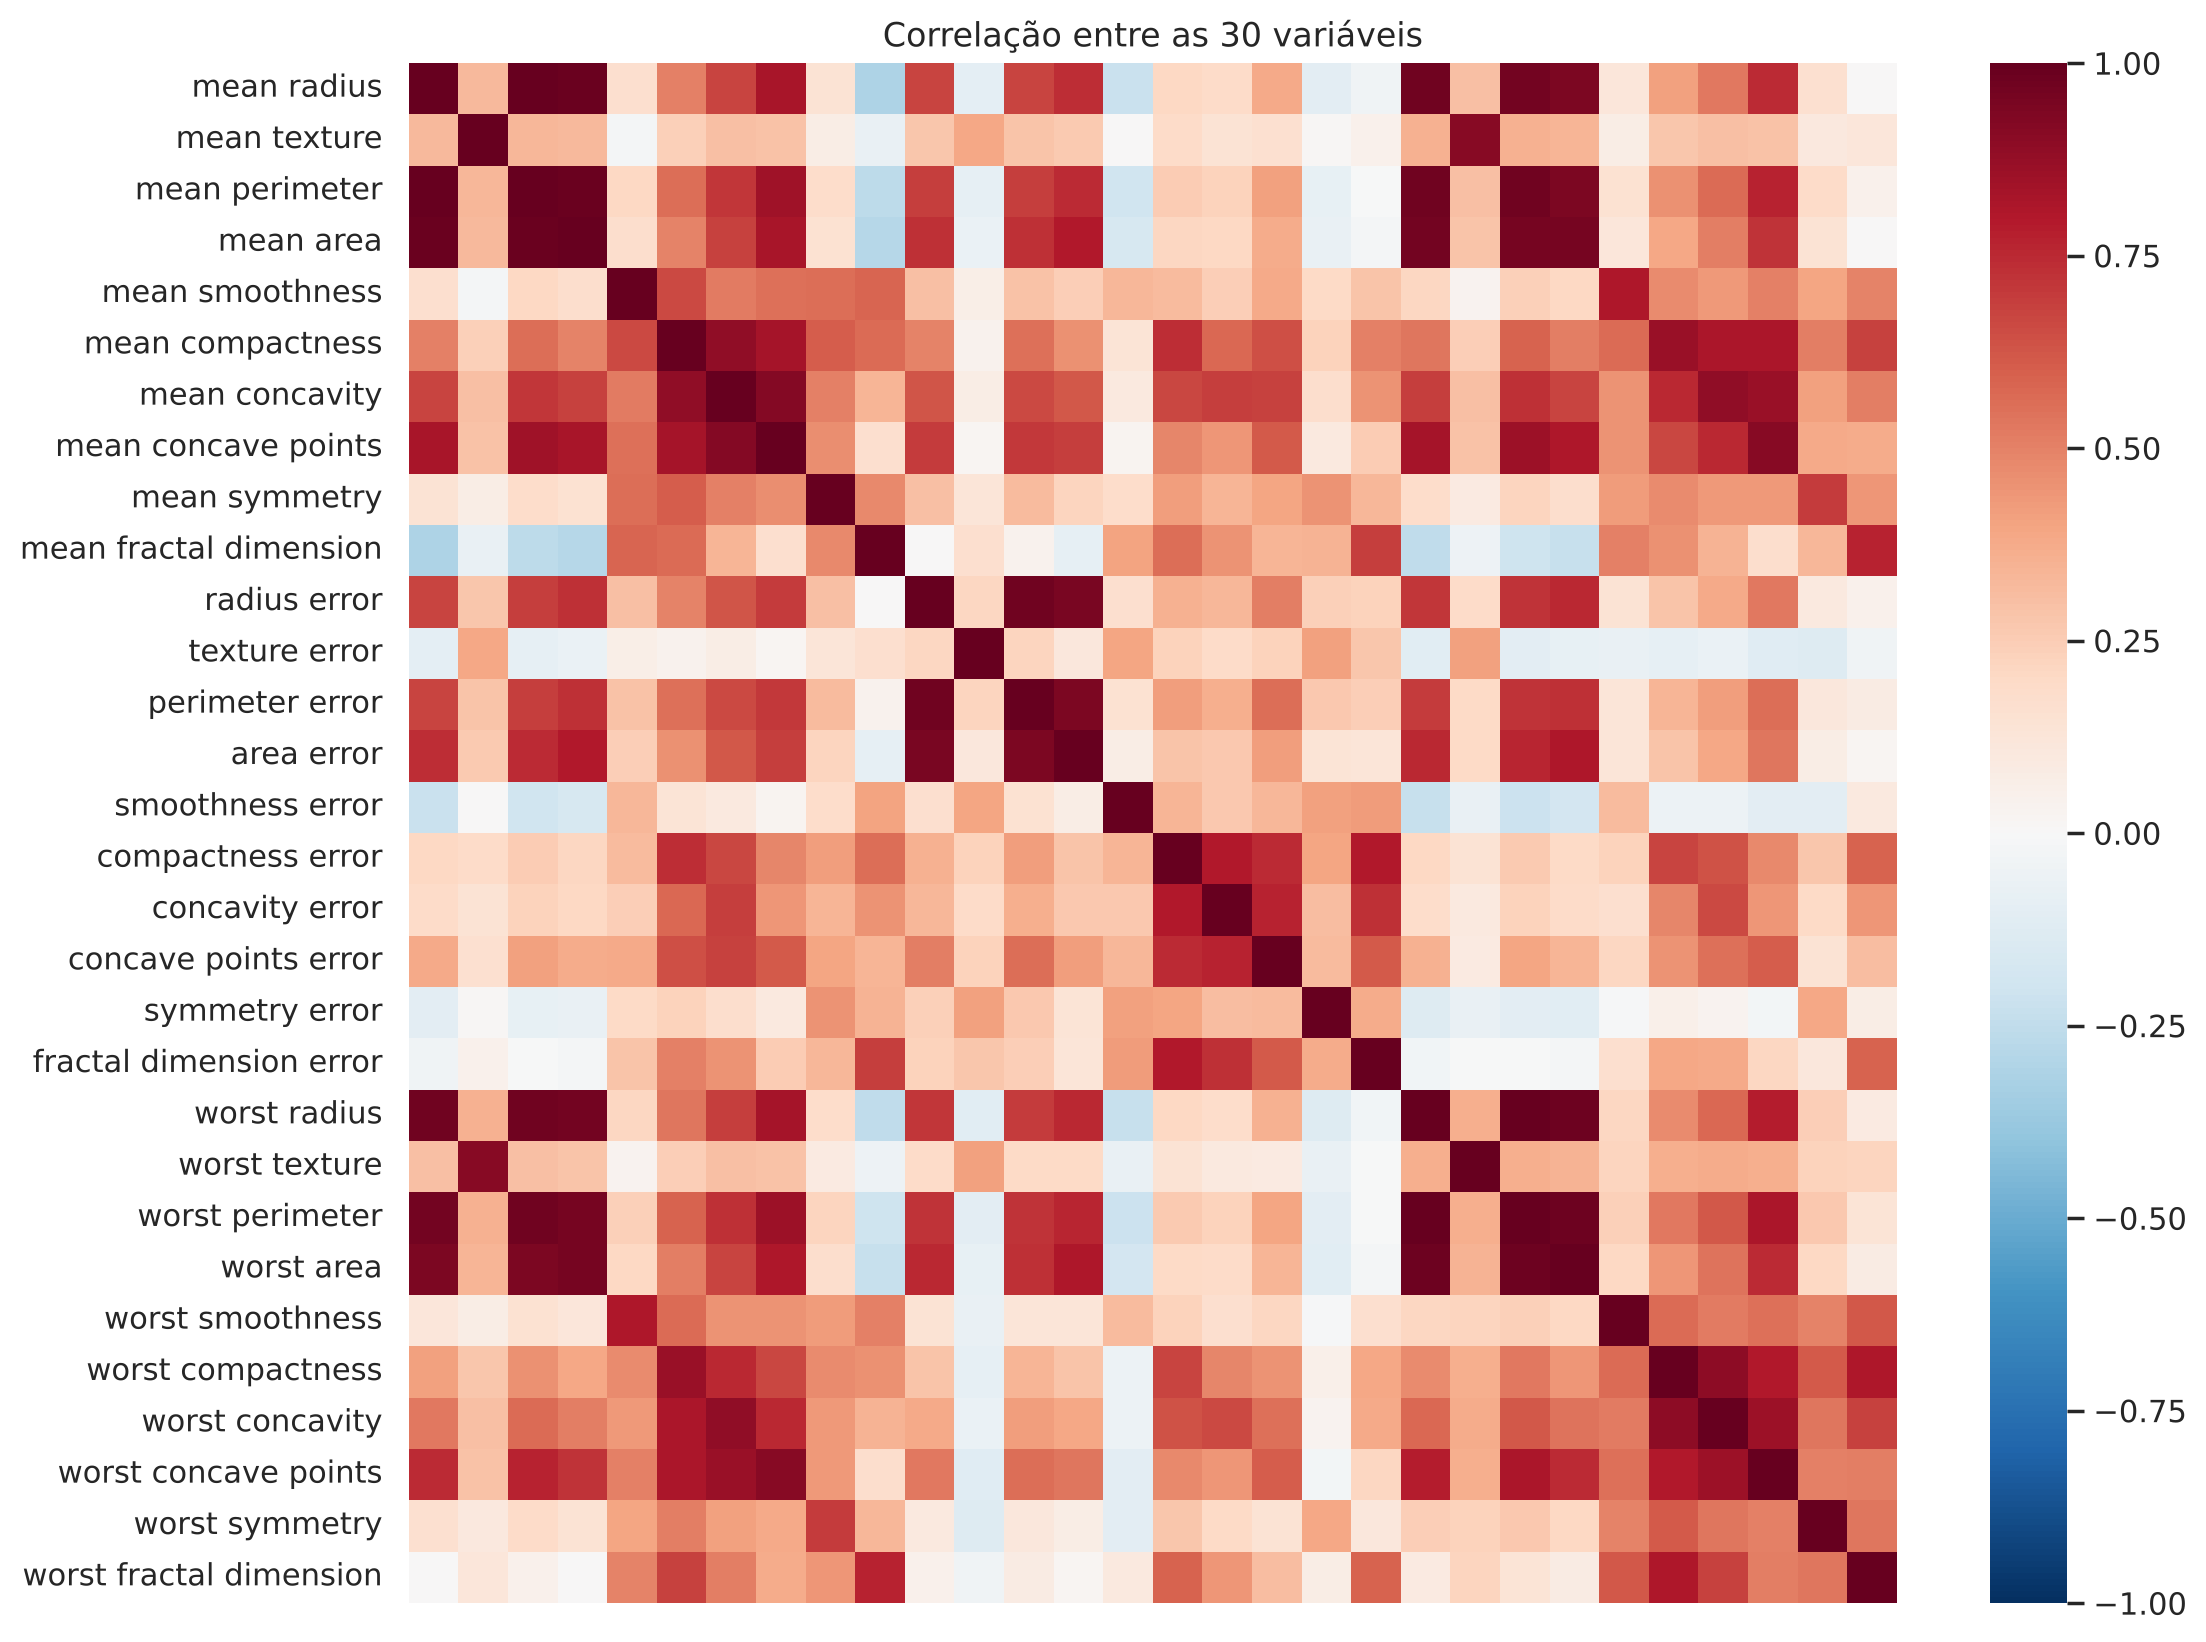

In [3]:
corr = X.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, xticklabels=False)
plt.title("Correlação entre as 30 variáveis")
plt.show()

### Tarefa 1 — Medindo a redundância
Conte quantos **pares de variáveis diferentes** têm correlação, em módulo, **maior que 0,9**.

Dica: a matriz é simétrica e a diagonal vale 1. Use só o triângulo superior: `np.triu(np.ones(corr.shape), k=1).astype(bool)`.

In [4]:
# Tarefa 1 — gabarito
triangulo = np.triu(np.ones(corr.shape), k=1).astype(bool)
pares = corr.where(triangulo).stack().dropna()
fortes = pares[pares.abs() > 0.9].sort_values(ascending=False)

print(f"Pares com |correlação| > 0,9: {len(fortes)} de {len(pares)}")
fortes.head(10)

Pares com |correlação| > 0,9: 21 de 435


mean radius      mean perimeter     0.997855
worst radius     worst perimeter    0.993708
mean radius      mean area          0.987357
mean perimeter   mean area          0.986507
worst radius     worst area         0.984015
worst perimeter  worst area         0.977578
radius error     perimeter error    0.972794
mean perimeter   worst perimeter    0.970387
mean radius      worst radius       0.969539
mean perimeter   worst radius       0.969476
dtype: float64

**Resposta (gabarito):** São 21 pares acima de 0,9, vários perto de 1 (raio × perímetro × área). Esse excesso de colinearidade deixa os coeficientes de modelos lineares instáveis, e é o cenário clássico em que a PCA pode ajudar.

---
# B — O erro mais comum: vazamento de dados

Um roteiro que aparece em muitos tutoriais (inclusive na versão anterior desta aula):

```python
scaled = StandardScaler().fit_transform(X)        # 1. padroniza com TODOS os dados
x_pca  = PCA(n_components=7).fit_transform(scaled) # 2. PCA com TODOS os dados
X_train, X_test, ... = train_test_split(x_pca, y)  # 3. só agora separa treino e teste
```

### Tarefa 2 — Onde está o problema?
Leia as três linhas acima. Que informação do **conjunto de teste** "vaza" para o modelo antes da avaliação? Por que isso é um problema, mesmo que a PCA não use o diagnóstico `y`?

**Resposta (gabarito):** Nas etapas 1 e 2, as **médias e desvios** do `StandardScaler` e as **direções** da PCA são calculadas usando também os tumores que depois serão o teste. O teste deixa de ser "dados nunca vistos": o pré-processamento já se adaptou a eles.

Mesmo sem usar `y`, isso torna a avaliação otimista. Em produção, um paciente novo será transformado com médias e direções aprendidas **sem ele**. Neste conjunto o efeito é pequeno (569 observações bem comportadas), mas em bases menores, ou com etapas que usam `y` (seleção de variáveis, *target encoding*), o efeito pode ser grande.

**Regra:** tudo o que é "aprendido" (`fit`) deve ver **somente o treino**.

---
# C — O jeito certo: separar primeiro, e usar `Pipeline`

1. Separamos um **conjunto de teste** que só será usado no final (Etapa E).
2. No treino, usamos **validação cruzada**: o treino é dividido em 5 partes, e cada parte serve de validação uma vez.
3. Um `Pipeline` encadeia **padronizar → PCA → classificador**. Em cada rodada da validação cruzada ele refaz o `fit` de todas as etapas **apenas com a parte de treino daquela rodada**. O vazamento fica impossível por construção.

In [5]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEMENTE)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

print("Treino:", X_treino.shape, " Teste:", X_teste.shape)

Treino: (398, 30)  Teste: (171, 30)


### Tarefa 3 — Montando o Pipeline
1. Crie `modelo_pca`: um `Pipeline` com três etapas:
   - `("padronizar", StandardScaler())`
   - `("pca", PCA(n_components=7))`
   - `("clf", LogisticRegression(max_iter=5000))`
2. Crie `modelo_base`: o mesmo, **sem** a etapa de PCA.
3. Avalie os dois com `cross_val_score(modelo, X_treino, y_treino, cv=cv, scoring="accuracy")` e mostre a **média ± desvio padrão**.

In [6]:
# Tarefa 3 — gabarito
modelo_pca = Pipeline([
    ("padronizar", StandardScaler()),
    ("pca", PCA(n_components=7)),
    ("clf", LogisticRegression(max_iter=5000)),
])
modelo_base = Pipeline([
    ("padronizar", StandardScaler()),
    ("clf", LogisticRegression(max_iter=5000)),
])

for nome, modelo in [("Sem PCA (30 variáveis)", modelo_base), ("Com PCA (7 componentes)", modelo_pca)]:
    notas = cross_val_score(modelo, X_treino, y_treino, cv=cv, scoring="accuracy")
    print(f"{nome:<26} acurácia = {notas.mean():.3f} ± {notas.std():.3f}")

Sem PCA (30 variáveis)     acurácia = 0.975 ± 0.008
Com PCA (7 componentes)    acurácia = 0.972 ± 0.015


---
# D — Quantas componentes? E a PCA compensa?

Em vez de escolher *k* "no olho", vamos **testar** vários valores e medir.

### Tarefa 4 — Acurácia × número de componentes
1. Para *k* de **1 a 30**, ajuste `modelo_pca` com `PCA(n_components=k)` e guarde a média e o desvio da acurácia na validação cruzada.
   Dica: `modelo_pca.set_params(pca__n_components=k)`.
2. Faça um gráfico da acurácia média × *k*, com uma **linha horizontal** marcando o `modelo_base` (sem PCA).
3. Qual *k* deu a maior acurácia? Ela é **muito** diferente do modelo sem PCA?

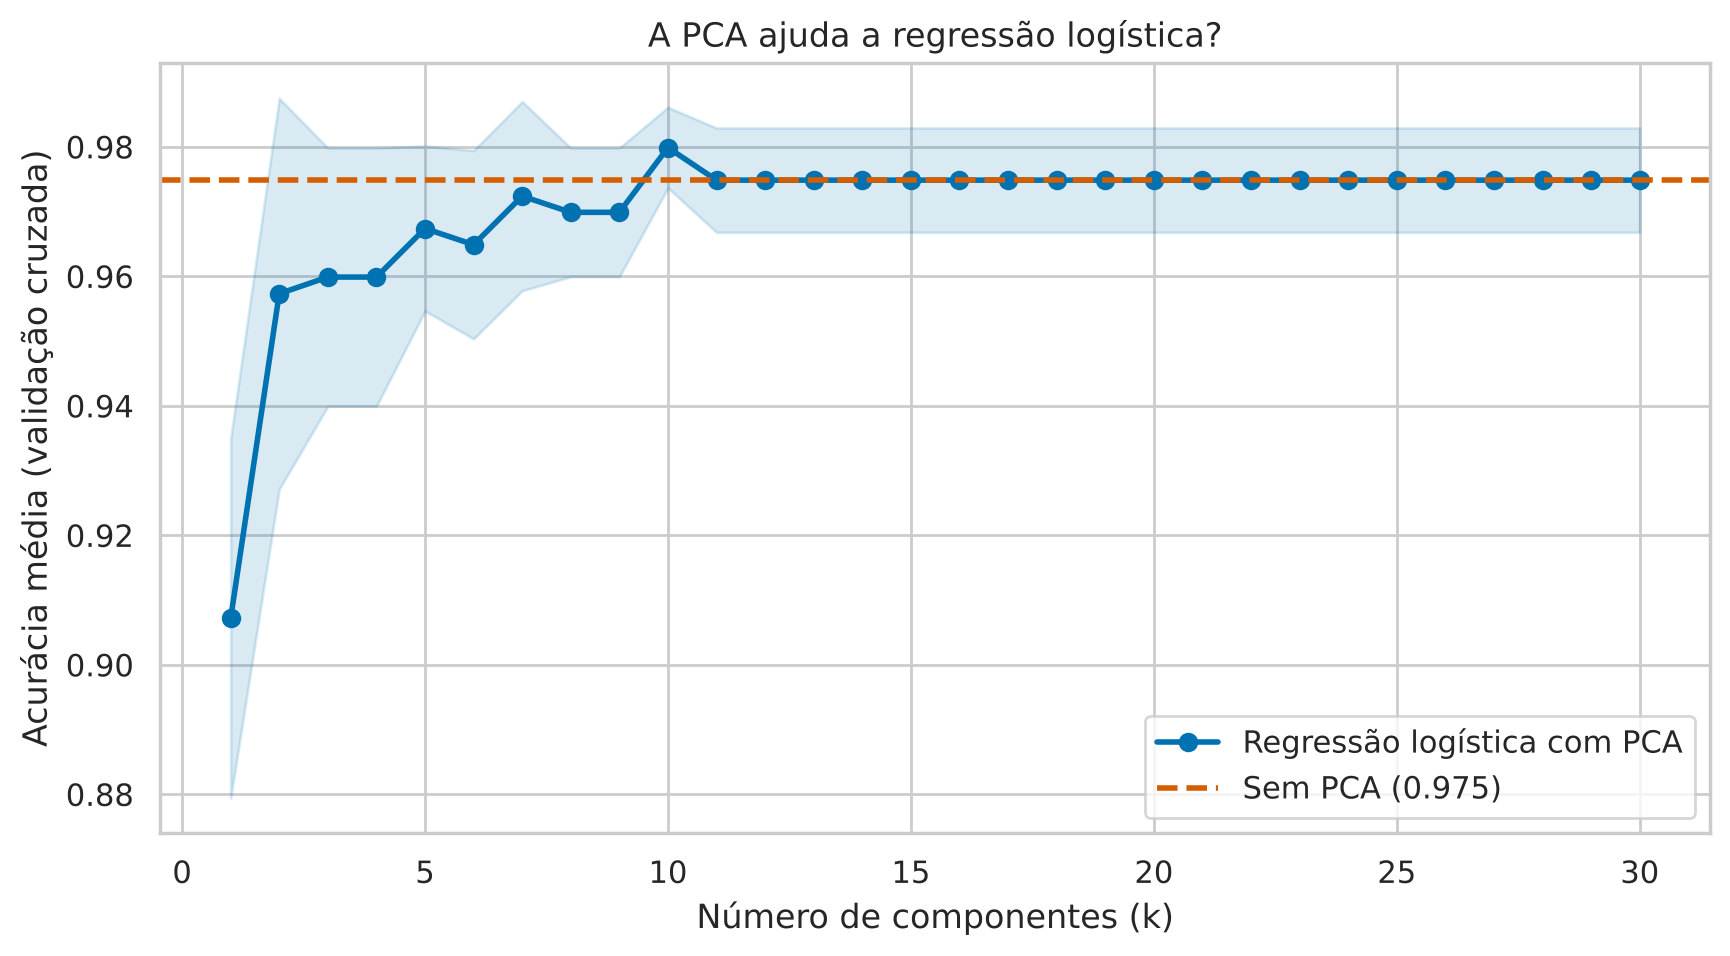

Melhor k = 10  ->  acurácia 0.980   |   sem PCA: 0.975


In [7]:
# Tarefa 4 — gabarito
ks = range(1, 31)
medias, desvios = [], []
for k in ks:
    modelo_pca.set_params(pca__n_components=k)
    notas = cross_val_score(modelo_pca, X_treino, y_treino, cv=cv, scoring="accuracy")
    medias.append(notas.mean()); desvios.append(notas.std())
medias, desvios = np.array(medias), np.array(desvios)

base = cross_val_score(modelo_base, X_treino, y_treino, cv=cv, scoring="accuracy").mean()
k_melhor = list(ks)[np.argmax(medias)]

plt.figure(figsize=(10, 5))
plt.plot(ks, medias, color="#0072B2", marker="o", lw=2, label="Regressão logística com PCA")
plt.fill_between(ks, medias - desvios, medias + desvios, color="#0072B2", alpha=0.15)
plt.axhline(base, color="#D55E00", ls="--", lw=2, label=f"Sem PCA ({base:.3f})")
plt.xlabel("Número de componentes (k)")
plt.ylabel("Acurácia média (validação cruzada)")
plt.title("A PCA ajuda a regressão logística?")
plt.legend(loc="lower right")
plt.show()

print(f"Melhor k = {k_melhor}  ->  acurácia {medias.max():.3f}   |   sem PCA: {base:.3f}")

**Resposta (gabarito):** Com 1 componente a acurácia já passa de 90%; ela sobe rapidamente até *k* ≈ 5–10 e depois fica estável. O melhor *k* empata (dentro da faixa de ± 1 desvio padrão) com o modelo sem PCA. **A PCA não "melhora" a acurácia aqui**, mas entrega o mesmo desempenho com bem menos variáveis.

### Tarefa 5 — Deixando a variância escolher *k*
Em vez de um número, `PCA(n_components=0.95)` mantém **quantas componentes forem necessárias para guardar 95% da variância**.

1. Ajuste `modelo_pca` com `pca__n_components=0.95` em **todo o treino** (`.fit`).
2. Descubra quantas componentes foram escolhidas: `modelo_pca.named_steps["pca"].n_components_`.
3. Avalie esse modelo na validação cruzada.

In [8]:
# Tarefa 5 — gabarito
modelo_pca.set_params(pca__n_components=0.95)
modelo_pca.fit(X_treino, y_treino)
k95 = modelo_pca.named_steps["pca"].n_components_
print(f"Componentes para 95% da variância: {k95}")

notas = cross_val_score(modelo_pca, X_treino, y_treino, cv=cv, scoring="accuracy")
print(f"Acurácia (validação cruzada): {notas.mean():.3f} ± {notas.std():.3f}")

Componentes para 95% da variância: 10
Acurácia (validação cruzada): 0.980 ± 0.006


### Tarefa 6 (desafio) — E com Random Forest?
Árvores de decisão não sofrem com colinearidade como os modelos lineares. Repita a Tarefa 4 trocando o classificador por `RandomForestClassifier(n_estimators=200, random_state=SEMENTE, n_jobs=-1)` e use apenas `ks = [1, 2, 3, 5, 7, 10, 15, 20, 30]` (para não demorar). A PCA ajuda ou atrapalha a floresta?

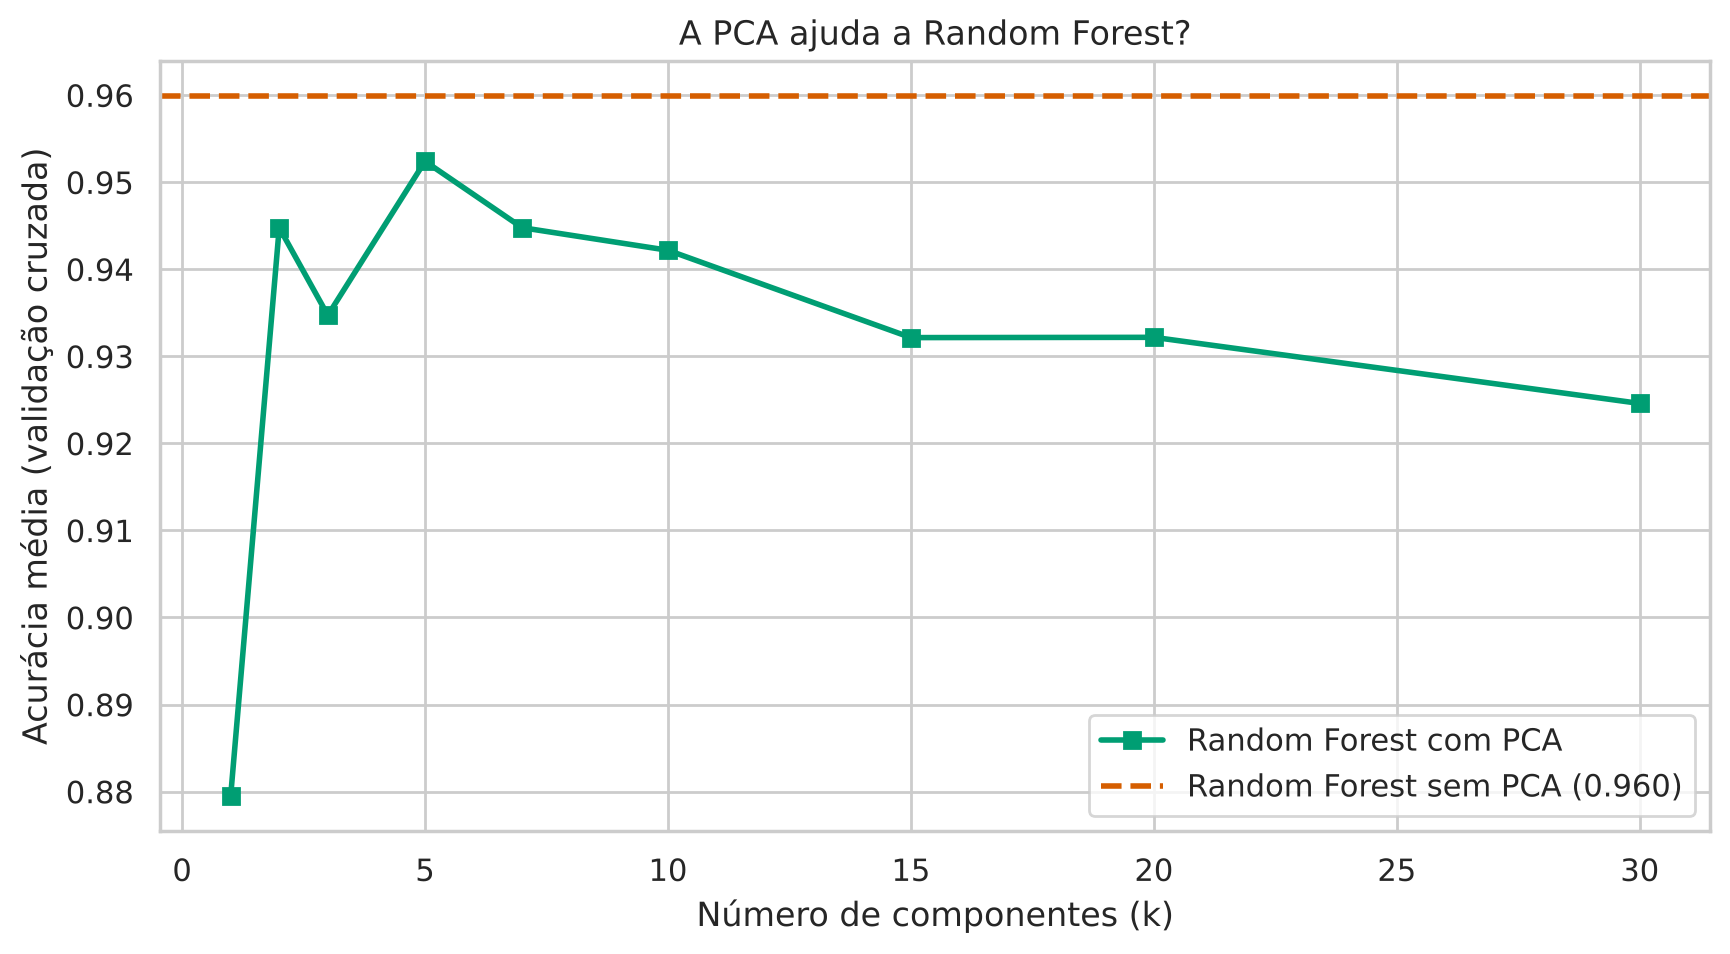

In [9]:
# Tarefa 6 — gabarito
ks_rf = [1, 2, 3, 5, 7, 10, 15, 20, 30]
rf_pca = Pipeline([
    ("padronizar", StandardScaler()),
    ("pca", PCA()),
    ("clf", RandomForestClassifier(n_estimators=200, random_state=SEMENTE, n_jobs=-1)),
])
rf_base = RandomForestClassifier(n_estimators=200, random_state=SEMENTE, n_jobs=-1)

medias_rf = []
for k in ks_rf:
    rf_pca.set_params(pca__n_components=k)
    medias_rf.append(cross_val_score(rf_pca, X_treino, y_treino, cv=cv).mean())
base_rf = cross_val_score(rf_base, X_treino, y_treino, cv=cv).mean()

plt.figure(figsize=(10, 5))
plt.plot(ks_rf, medias_rf, color="#009E73", marker="s", lw=2, label="Random Forest com PCA")
plt.axhline(base_rf, color="#D55E00", ls="--", lw=2, label=f"Random Forest sem PCA ({base_rf:.3f})")
plt.xlabel("Número de componentes (k)")
plt.ylabel("Acurácia média (validação cruzada)")
plt.title("A PCA ajuda a Random Forest?")
plt.legend(loc="lower right")
plt.show()

**Resposta (gabarito):** A floresta sem PCA já é muito boa, e com PCA ela fica parecida ou um pouco pior. As árvores escolhem sozinhas as variáveis úteis e não se incomodam com redundância; ao misturar as variáveis em componentes, a PCA pode até "diluir" uma variável que separava bem as classes.

---
# E — Avaliação final no conjunto de teste

Só agora, **uma única vez**, usamos o teste.

### Tarefa 7 — O veredito
1. Escolha um modelo (por exemplo, a regressão logística com o `k_melhor` da Tarefa 4).
2. Ajuste-o em **todo o treino**, preveja o **teste** e mostre:
   - a acurácia;
   - a matriz de confusão (rótulos `["maligno", "benigno"]`);
   - o `classification_report`.
3. Quantos tumores **malignos** foram classificados como benignos? Por que esse erro importa mais que o contrário?

Acurácia no teste (k = 10): 0.971

              precision    recall  f1-score   support

     maligno       0.94      0.98      0.96        64
     benigno       0.99      0.96      0.98       107

    accuracy                           0.97       171
   macro avg       0.97      0.97      0.97       171
weighted avg       0.97      0.97      0.97       171



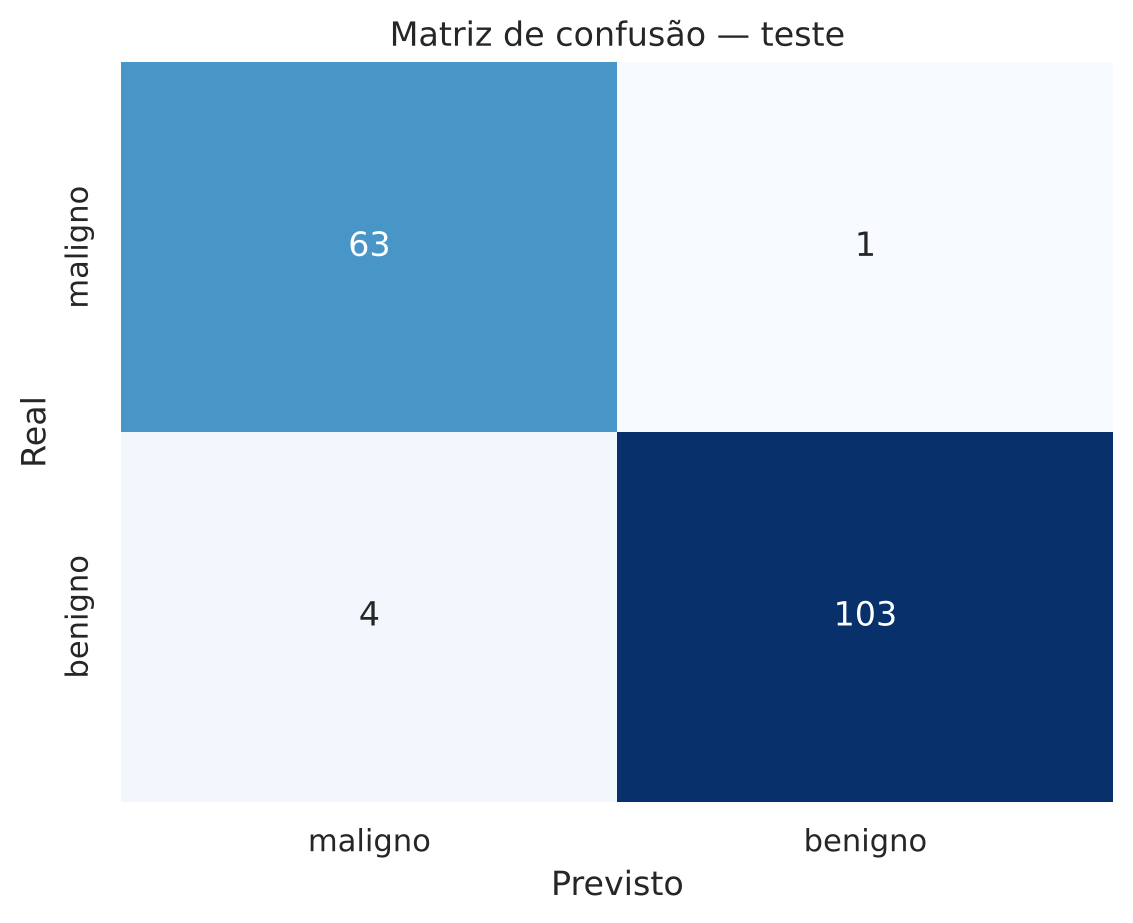

In [10]:
# Tarefa 7 — gabarito
modelo_final = Pipeline([
    ("padronizar", StandardScaler()),
    ("pca", PCA(n_components=k_melhor)),
    ("clf", LogisticRegression(max_iter=5000)),
])
modelo_final.fit(X_treino, y_treino)
y_prev = modelo_final.predict(X_teste)

print(f"Acurácia no teste (k = {k_melhor}): {accuracy_score(y_teste, y_prev):.3f}\n")
rotulos = ["maligno", "benigno"]
print(classification_report(y_teste, y_prev, target_names=rotulos))

sns.heatmap(confusion_matrix(y_teste, y_prev), annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=rotulos, yticklabels=rotulos)
plt.xlabel("Previsto"); plt.ylabel("Real")
plt.title("Matriz de confusão — teste")
plt.show()

**Resposta (gabarito):** A acurácia no teste fica próxima da validação cruzada, sinal de que a avaliação foi honesta. Na matriz de confusão, a célula *real = maligno, previsto = benigno* é o **falso negativo**: um câncer que o modelo deixaria passar. Esse erro custa muito mais que um falso positivo (que leva a um exame extra). Por isso o *recall* da classe maligno importa mais que a acurácia geral.

---
# Quando a PCA compensa em um modelo?

| Compensa | Não compensa |
|---|---|
| Muitas variáveis **muito correlacionadas** em modelos lineares | Modelos de árvore (Random Forest, Gradient Boosting) |
| Mais variáveis que observações (*p* ≫ *n*): genômica, sensores, texto | Quando é preciso **explicar** o modelo variável por variável |
| Reduzir custo de treino e armazenamento | Poucas variáveis, pouco correlacionadas |
| Remover ruído de medições | Quando a informação que separa as classes está em direções de **pouca** variância |

**Dois lembretes:**
- A PCA **não usa o `y`**: a direção de maior variância não é necessariamente a que melhor separa as classes.
- Num relatório para o médico, "o raio do núcleo é o fator mais importante" é útil; "a PC3 é importante" não é. **Interpretabilidade tem valor.**

## Fique Conectado

- [![YouTube](https://raw.githubusercontent.com/EduPekUfpr/PythonProject/refs/heads/main/Images/youtube_icon_color.png)](https://www.youtube.com/@LigaDataScience/videos)  
  Explore nossos vídeos educacionais e webinars sobre ciência de dados, machine learning e inteligência artificial. Inscreva-se para não perder nenhuma atualização!

- [![LinkedIn](https://raw.githubusercontent.com/EduPekUfpr/PythonProject/refs/heads/main/Images/linkedin_icon_color.png)](https://www.linkedin.com/company/liga-data-science-ufpr/)  
  Siga-nos no LinkedIn para as últimas novidades, oportunidades de carreira e networking profissional no campo da ciência de dados.

- [![Instagram](https://raw.githubusercontent.com/EduPekUfpr/PythonProject/refs/heads/main/Images/instagram_icon_color.png)](https://www.instagram.com/ligadatascience/)  
  Confira nosso Instagram para conteúdos dos bastidores, destaques de eventos e o dia a dia da Liga Data Science. Faça parte da nossa jornada!

_______

## Autor

<a href="https://www.linkedin.com/in/eduardopecora/" target="_blank">Eduardo Pecora</a>

## Referências

* <a href="https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html">Scikit-learn: PCA</a>
* <a href="https://scikit-learn.org/stable/modules/compose.html">Scikit-learn: Pipelines</a>
* <a href="https://scikit-learn.org/stable/common_pitfalls.html">Scikit-learn: Common pitfalls (data leakage)</a>
* <a href="https://scikit-learn.org/stable/modules/cross_validation.html">Scikit-learn: Cross-validation</a>

## Log de modificações

| Data | Versão | Modificado por | Descrição |
| ----------------- | ------- | ---------- | ---------------------------------- |
| 24-10-2021       | 1.0     | Eduardo Pecora | Criação (aula única de PCA) |
| 09-11-2026       | 2.0     | Claude (a pedido de Eduardo Pécora) | Notebook próprio: vazamento, Pipeline, validação cruzada e escolha de k; cabeçalho/rodapé LDS |

<hr>

## <h3 align="center"> (c) LDS / UFPR 2026. All rights reserved. <h3/>